In [40]:
#Import modules
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.colors as mcolors
import cartopy.io.img_tiles as cimgt
import cartopy.io.shapereader as shpreader
import shapely.geometry as sgeom
from shapely.ops import unary_union
from shapely.prepared import prep
import pandas as pd
import shapely.vectorized
import geopandas as gpd
from shapely.geometry import Point
import random
from datetime import datetime

In [41]:
filename = f"/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/Databases/reentry_info_2020.nc"
ds = xr.open_dataset(filename, decode_times=False)
#ds

In [42]:
pd.set_option('display.max_rows', None)
df = pd.DataFrame(
    {
        "ID":               ds["RE_ID"].values,
        "Name":             ds["RE_Name"].values,
        "Type":             ds["RE_Type"].values,
        "Burnup":           ds["RE_Burnup"].values,
        "Stage":            ds["RE_Stage"].values,
        "Lat":              ds["RE_Lat"].values,
        "Lon":              ds["RE_Lon"].values,   
        "Time":             ds["RE_Time"].values,
        "Mon":              ds["RE_Mon"].values,
        "Day":              ds["RE_Day"].values,     
        "Mass":             ds["RE_Mass"].values,
        "MCS":              ds["RE_MCS"].values,
        "Manual Location":  ds["RE_Manual_Loc"].values,
    }
)

#df.sort_values("Lon", ascending=False)

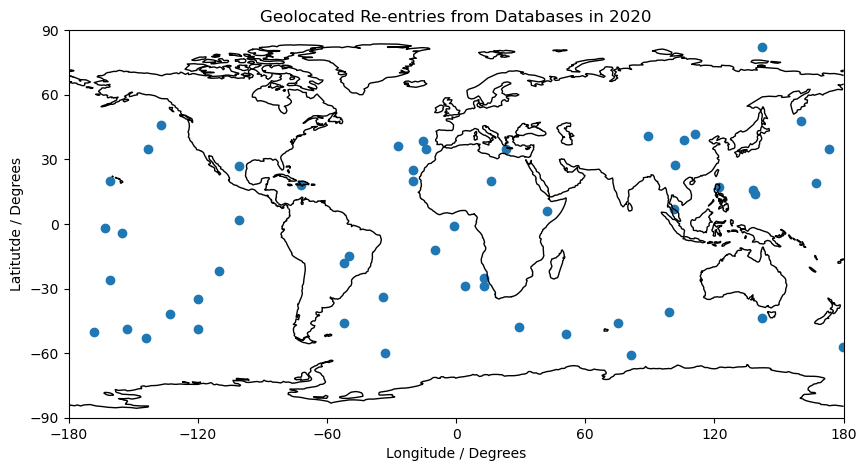

In [43]:
# First print all re-entries with location information.
# We need to base our assignment on existing relevant re-entry events (complete burnup only, not manually assigned to launch site).

df2 = df.loc[(df["Lat"] != 0) & (df["Manual Location"] == False) & (df["Burnup"] == "Complete")]
plot_array = np.array([])
geo_list = []
for i in range(len(df2["Lat"])):
    plot_array = np.append(plot_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
    geo_list.append(df2["ID"].values[i])
                   
fig = plt.figure(figsize=[10, 6])
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.scatter(plot_array[1::2],plot_array[::2]) 
ax.set_xlim(-180,180)
ax.set_ylim(-90,90)
ax.set_xticks(np.linspace(-180,180,7))
ax.set_yticks(np.linspace(-90,90,7))
ax.set_xlabel("Longitude / Degrees")
ax.set_ylabel("Latitutde / Degrees")
ax.set_title("Geolocated Re-entries from Databases in 2020");

In [44]:
# Load in shapefiles for the oceans and countries, and create subspaces for individual regions.

ocean_shapefile = gpd.read_file("/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/Databases/GOaS_v1_20211214/goas_v01.shp") 
# https://www.marineregions.org/downloads.php#iho
north_pacific    = ocean_shapefile[ocean_shapefile.name.isin(['North Pacific Ocean'])]
south_pacific    = ocean_shapefile[ocean_shapefile.name.isin(['South Pacific Ocean'])]
north_atlantic   = ocean_shapefile[ocean_shapefile.name.isin(['North Atlantic Ocean'])]
south_atlantic   = ocean_shapefile[ocean_shapefile.name.isin(['South Atlantic Ocean'])]
indian_ocean     = ocean_shapefile[ocean_shapefile.name.isin(['Indian Ocean'])]
south_ocean      = ocean_shapefile[ocean_shapefile.name.isin(['Southern Ocean'])]
mediterranean    = ocean_shapefile[ocean_shapefile.name.isin(['Mediterranean Region'])]
east_asia_seas   = ocean_shapefile[ocean_shapefile.name.isin(['South China and Easter Archipelagic Seas'])] 
baltic           = ocean_shapefile[ocean_shapefile.name.isin(['Baltic Sea'])] 
arctic           = ocean_shapefile[ocean_shapefile.name.isin(['Arctic Ocean'])] 

# Using the United Nations geoscheme to group countries.
countries_shapefile = gpd.read_file("/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/Databases/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp") 
central_america     = countries_shapefile[countries_shapefile.NAME.isin(['Mexico', 'Belize', 'Costa Rica', 'El Salvador', 'Guatemala', 'Honduras', 'Mexico', 'Nicaragua', 'Panama'])]

south_america       = countries_shapefile[countries_shapefile.NAME.isin(['Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 
                                                                         'Guyana', 'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela'])]

east_asia           = countries_shapefile[countries_shapefile.NAME.isin(['China', 'North Korea', 'Japan', 'Mongolia', 'South Korea'])]

south_east_asia     = countries_shapefile[countries_shapefile.NAME.isin(['Brunei', 'Cambodia', 'Indonesia', 'Laos', 'Malaysia', 'Myanmar',
                                                                         'Philippines', 'Thailand', 'East Timor', 'Vietnam'])]

east_africa         = countries_shapefile[countries_shapefile.NAME.isin(['Burundi', 'Djibouti', 'Eritrea', 'Ethiopia', 'Kenya', 'Malawi', 'Mozambique', 'Rwanda', 
                                                                         'Somalia', 'South Sudan', 'Uganda', 'United Republic of Tanzania', 'Zambia', 'Zimbabwe'])] 

mid_africa          = countries_shapefile[countries_shapefile.NAME.isin(['Angola', 'Cameroon', 'Central African Republic', 'Chad', 'Republic of the Congo', 
                                                                         'Democratic Republic of the Congo', 'Equatorial Guinea', 'Gabon'])]

central_america_union   = gpd.GeoDataFrame(geometry=[central_america.unary_union])
south_america_union     = gpd.GeoDataFrame(geometry=[south_america.unary_union])
east_asia_union         = gpd.GeoDataFrame(geometry=[east_asia.unary_union])
south_east_asia_union   = gpd.GeoDataFrame(geometry=[south_east_asia.unary_union])
east_africa_union       = gpd.GeoDataFrame(geometry=[east_africa.unary_union])
mid_africa_union        = gpd.GeoDataFrame(geometry=[mid_africa.unary_union])

In [45]:
# Create a function to differentiate between land or not.   
shpfilename  = shpreader.natural_earth(resolution='10m', category='physical', name='land')
reader = shpreader.Reader(shpfilename)
countries = list(reader.records())
land_geom = unary_union(
    [record.geometry
     for record in shpreader.Reader(shpfilename ).records()
     if record.attributes.get('featurecla') != "Null island"])
land = prep(land_geom)
def is_land(x, y):
   return land.contains(sgeom.Point(x, y))

In [46]:
# Now determine in which region each existing re-entry is, and plot the remaining re-entry events.
np_array, sp_array, na_array, sa_array = np.array([]), np.array([]), np.array([]), np.array([])
io_array, so_array, med_array, eas_array = np.array([]), np.array([]), np.array([]), np.array([])
bal_array, arc_array, other_array = np.array([]), np.array([]), np.array([])
cen_am_array, sou_am_array, east_as_array, east_africa_array, mid_africa_array, south_east_as_array = np.array([]), np.array([]), np.array([]), np.array([]), np.array([]), np.array([])

for i in range(len(df2["Lat"])):
    coordinate = Point(df2["Lon"].values[i],df2["Lat"].values[i])
    if is_land(df2["Lon"].values[i],df2["Lat"].values[i]) != True:
        if north_pacific.geometry.contains(coordinate).any():
            np_array = np.append(np_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif south_pacific.geometry.contains(coordinate).any():
            sp_array = np.append(sp_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif north_atlantic.geometry.contains(coordinate).any():
            na_array = np.append(na_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif south_atlantic.geometry.contains(coordinate).any():
            sa_array = np.append(sa_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif indian_ocean.geometry.contains(coordinate).any():
            io_array = np.append(io_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif mediterranean.geometry.contains(coordinate).any():
            med_array = np.append(med_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif south_ocean.geometry.contains(coordinate).any():
            so_array = np.append(so_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif east_asia_seas.geometry.contains(coordinate).any():
            eas_array = np.append(eas_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif baltic.geometry.contains(coordinate).any():
            bal_array = np.append(bal_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif arctic.geometry.contains(coordinate).any():
            arc_array = np.append(arc_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
    else:
        if central_america_union.geometry.contains(coordinate).any():
            cen_am_array = np.append(cen_am_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif south_america_union.geometry.contains(coordinate).any():
            sou_am_array = np.append(sou_am_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif east_asia_union.geometry.contains(coordinate).any():
            east_as_array = np.append(east_as_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif south_east_asia_union.geometry.contains(coordinate).any():
            south_east_as_array = np.append(south_east_as_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0)
        elif east_africa_union.geometry.contains(coordinate).any():
            east_africa_array = np.append(east_africa_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0) 
        elif mid_africa_union.geometry.contains(coordinate).any():
            mid_africa_array = np.append(mid_africa_array, [df2["Lat"].values[i], df2["Lon"].values[i]], axis=0) 

[9.0, 11.0, 6.0, 7.0, 5.0, 1.0, 2.0, 1.0, 0.0, 1.0, 0, 0, 0, 0, 0, 0]
53 43.0
[20.93 25.58 13.95 16.28 11.63  2.33  4.65  2.33  0.    2.33  0.    0.
  0.    0.    0.    0.  ]


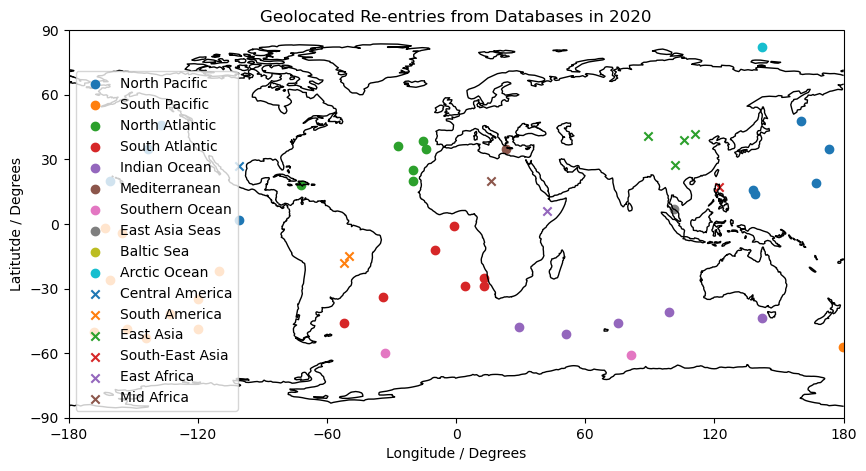

In [47]:
weight_array = [len(np_array)/2,
                len(sp_array)/2,
                len(na_array)/2,
                len(sa_array)/2,
                len(io_array)/2,
                len(med_array)/2,
                len(so_array)/2,
                len(eas_array)/2,
                len(bal_array)/2,
                len(arc_array)/2,
                0, #len(cen_am_array)/2,
                0, #len(sou_am_array)/2,
                0, #len(east_as_array)/2,
                0, #len(south_east_as_array)/2,
                0, #len(east_africa_array)/2,
                0, #len(mid_africa_array)/2,
                ]

print(weight_array)
print(len(df2["Lat"]),np.sum(weight_array))
weight_array = np.round((weight_array / np.sum(weight_array) * 100) , 2)
print(weight_array)

fig = plt.figure(figsize=[10, 6])
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.scatter(np_array[1::2],           np_array[::2], label = "North Pacific") 
ax.scatter(sp_array[1::2],           sp_array[::2], label = "South Pacific") 
ax.scatter(na_array[1::2],           na_array[::2], label = "North Atlantic") 
ax.scatter(sa_array[1::2],           sa_array[::2], label = "South Atlantic") 
ax.scatter(io_array[1::2],           io_array[::2], label = "Indian Ocean") 
ax.scatter(med_array[1::2],          med_array[::2], label = "Mediterranean") 
ax.scatter(so_array[1::2],           so_array[::2], label = "Southern Ocean") 
ax.scatter(eas_array[1::2],          eas_array[::2], label = "East Asia Seas") 
ax.scatter(bal_array[1::2],          bal_array[::2], label = "Baltic Sea") 
ax.scatter(arc_array[1::2],          arc_array[::2], label = "Arctic Ocean") 
ax.scatter(cen_am_array[1::2],       cen_am_array[::2], label = "Central America", marker = 'x') 
ax.scatter(sou_am_array[1::2],       sou_am_array[::2], label = "South America", marker = 'x') 
ax.scatter(east_as_array[1::2],      east_as_array[::2], label = "East Asia", marker = 'x') 
ax.scatter(south_east_as_array[1::2],      south_east_as_array[::2], label = "South-East Asia", marker = 'x') 
ax.scatter(east_africa_array[1::2],  east_africa_array[::2], label = "East Africa", marker = 'x') 
ax.scatter(mid_africa_array[1::2],   mid_africa_array[::2], label = "Mid Africa", marker = 'x') 
ax.legend(loc="lower left") 
ax.set_xlim(-180,180)
ax.set_ylim(-90,90)
ax.set_xticks(np.linspace(-180,180,7))
ax.set_yticks(np.linspace(-90,90,7))
ax.set_xlabel("Longitude / Degrees")
ax.set_ylabel("Latitutde / Degrees")
ax.set_title("Geolocated Re-entries from Databases in 2020");

In [48]:
# Randomly assign a location to each entry that is missing a geolocation tag.

def weighted_choice(weights):
    totals = []
    running_total = 0

    for w in weights:
        running_total += w
        totals.append(running_total)

    rnd = random.random() * running_total
    for i, total in enumerate(totals):
        if rnd < total:
            return i
        
region_list = [north_pacific, 
               south_pacific, 
               north_atlantic, 
               south_atlantic,  
               indian_ocean,   
               south_ocean,    
               mediterranean,   
               east_asia_seas,  
               baltic,         
               arctic,         
               central_america_union,       
               south_america_union,      
               east_asia_union,   
               south_east_asia_union,       
               east_africa_union,
               mid_africa_union,            
            ]

manual_points_array, new_points_array = np.array([]), np.array([])
for i in range(len(ds["RE_Lat"])):
    if ds["RE_Lon"].values[i] == 0 and ds["RE_Lat"].values[i] == 0:
        # Randomly select a region based on the existing re-entries.
        location_index = weighted_choice(weight_array)
        # Select a random lat, lon within this region and set it as the coordinates.
        random_location = region_list[location_index].sample_points(1).get_coordinates()
        ds["RE_Lon"].values[i] = random_location["x"].values[0]
        ds["RE_Lat"].values[i] = random_location["y"].values[0]
        new_points_array = np.append(new_points_array, [ds["RE_Lat"].values[i], ds["RE_Lon"].values[i]], axis=0)
    else:
        if ds["RE_ID"].values[i] not in geo_list:
            manual_points_array = np.append(manual_points_array, [ds["RE_Lat"].values[i], ds["RE_Lon"].values[i]], axis=0)
  

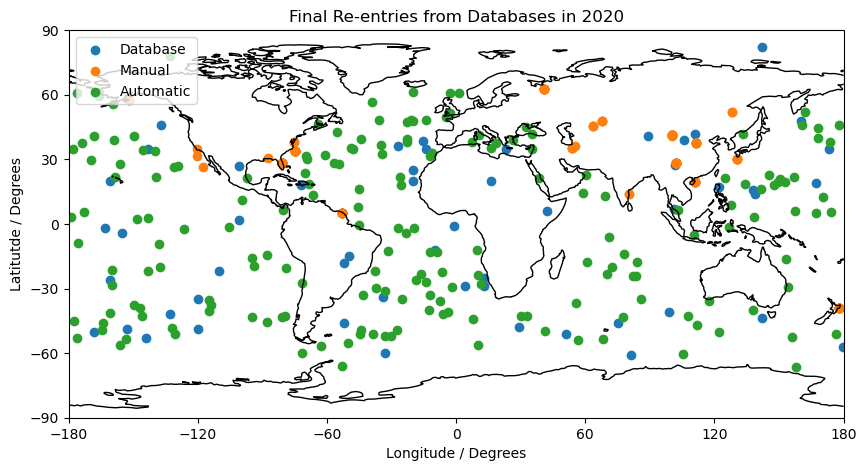

In [49]:
fig = plt.figure(figsize=[10, 6])
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.scatter(plot_array[1::2],plot_array[::2],label="Database") 
ax.scatter(manual_points_array[1::2],manual_points_array[::2],label="Manual") # From original database geolocated re-entries plot
ax.scatter(new_points_array[1::2],new_points_array[::2],label="Automatic") # Final re-entries after added lat/lon data
ax.set_xlim(-180,180)
ax.set_ylim(-90,90)
ax.set_xticks(np.linspace(-180,180,7))
ax.legend(loc='upper left')
ax.set_yticks(np.linspace(-90,90,7))
ax.set_xlabel("Longitude / Degrees")
ax.set_ylabel("Latitutde / Degrees")
ax.set_title("Final Re-entries from Databases in 2020");

In [50]:
pd.set_option('display.max_rows', None)
df_print = pd.DataFrame(
    {
        "ID":               ds["RE_ID"].values,
        "Name":             ds["RE_Name"].values,
        "Type":             ds["RE_Type"].values,
        "Burnup":           ds["RE_Burnup"].values,
        "Stage":            ds["RE_Stage"].values,
        "Lat":              ds["RE_Lat"].values,
        "Lon":              ds["RE_Lon"].values,   
        "Time":             ds["RE_Time"].values,
        "Mon":              ds["RE_Mon"].values,
        "Day":              ds["RE_Day"].values,     
        "Mass":             ds["RE_Mass"].values,
        "MCS":              ds["RE_MCS"].values,
        "Manual Location":  ds["RE_Manual_Loc"].values,
    }
)

df_print.sort_values("ID", ascending=True)

,ID,Name,Type,Burnup,Stage,Lat,Lon,Time,Mon,Day,Mass,MCS,Manual Location
4,1963-014EZ,West Ford dipoles,Component,Complete,5,-19.835460,-137.503947,0.000000,11,08,0.000,False,False
259,1964-054A,OGO 1,Payload,Complete,5,-27.779692,11.602884,0.000000,8,29,482.660,False,True
0,1973-056B,Agena D,R/B,Complete,3,-42.887544,107.542037,13.500000,02,25,600.000,False,False
1,1976-080A,OPS 7940,Payload,Complete,5,-46.000000,-52.000000,13.683333,04,18,650.000,False,False
2,1977-010A,Molniya-2,Payload,Complete,5,-49.424534,-27.419209,0.000000,01,06,1620.000,False,False
3,1986-014D,USA-17 cover?,Component,Complete,5,-53.467447,68.120949,0.000000,12,07,0.000,False,False
5,1989-097B,Delta 190,R/B,Complete,2,35.000000,173.000000,8.500000,03,11,919.000,False,False
228,1992-021C,Ariane 44L+ R/B,R/B,Complete,3,48.237710,-36.035397,10.700000,10,01,2080.000,False,False
6,1997-012B,DMSP F-14 solar array band?,Component,Complete,5,19.426953,152.609322,0.000000,10,26,0.000,False,False
25,1998-067HT,Diwata-1,Payload,Complete,5,30.040390,-69.389834,20.000000,04,05,50.000,False,False


In [51]:
#Save to file and close the DataSet     
now = datetime.now()
dt_string = now.strftime("%d%m%Y_%H%M%S")
ds.to_netcdf(f'./Databases/reentry_info_2020_updated_{dt_string}.nc')
ds.close()